# Photometry and Cotrending: Building and Believing Light Curves

Problem VIIIa of
[DSFP Session 27](https://github.com/LSSTC-DSFP/Session-27).
Timeline:

* **10:00**: Problems 1 to 4.
* **10:45**: Read "Before the break", after Problem 4.
* **10:50**: Break!
* **If you finish early**: There is an extra problem at the end.

* * *

By Luke Bouma (Caltech/IPAC)

## Learning Goals

By the end of this notebook, you will be able to:
1. Extract a light curve from images, and localize a variable source
   with a difference image
2. Find shared systematics with PCA over control stars, and spot a
   control that knows about your signal
3. Measure what a correction does to signals of different timescales
4. Test whether a fitted correction predicts data it has not seen

## Problems

* [Problem 1) Pixels](#Problem-1\)-Pixels)
* [Problem 2) Cotrending](#Problem-2\)-Cotrending)
* [Problem 3) Filter response](#Problem-3\)-Filter-response)
* [Problem 4) Prediction](#Problem-4\)-Prediction)
* [Before the break](#Before-the-break)
* [Extra](#Extra)

*Recap:* the lecture included four exhortations.  There is one
problem for each.

1. If you use a time series, **look at the data one level below
   it**.  (Problem 1)
2. If you see a signal in one source, **look at your controls**.
   (Problem 2)
3. If you clean your data, **inject signals and measure what
   survives**.  (Problem 3)
4. If you fit a flexible model, **check that it predicts data it has
   not seen**.  (Problem 4)

Our data are one TESS sector of a young star in Orion with a
periodic signal.  TESS pixels are 21 arcseconds across, and Orion is
crowded.  We are going to try and figure out which star in this field is the
one that is varying.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

import px_helpers as px

# interactive plots require ipympl:
# pip install ipympl if you don't have it
#%matplotlib ipympl
plt.rcParams["figure.max_open_warning"] = 0

`px_helpers.py` contains loaders and a few plotting helpers.
`px.load_star()` returns a dictionary, with the same keys for every
star we will look at today.  The cell after next lists them.

**The data.**  TESS is a space telescope that stares at one patch of sky for
about 27 days (a *sector*) and takes an image every 10 minutes (a
*cadence*).  Its pixels are 21 arcseconds per side; its PSF yields half the
light from a star within a single pixel, and 90% within a 4x4 pixel box.
For each star, the mission pipeline gives you three products:

1. A small movie of the pixels around the star, here 11 x 11: the
   *target pixel file*, `star["tpf"]`.
2. The *aperture*, the set of pixels the pipeline chose to sum:
   `star["aperture"]`.  Their sum at each cadence is the raw light
   curve, `star["sap"]` ("simple aperture photometry", SAP).
3. A corrected light curve with instrument trends removed,
   `star["pdcsap"]`.  We will not use it in this notebook.  In
   Problem 2 you build that correction yourself.

Three more things are in the dictionary:

4. `star["nbr_flux"]`: raw light curves of 50 other stars on the
   same detector, at the same cadences.  These are the controls
   for Problem 2.
5. `star["wide"]`: a wider movie, 25 x 25 pixels, cut from the
   full-frame images.  It is binned to one frame per hour to keep
   the file small, so it has 576 frames where everything else has
   3424, and its own time axis, `star["wide_time"]`.
6. `star["cbvs"]`: the pipeline's own systematics vectors.  Not used in
   this notebook.

Stars are named by their number in the TESS Input Catalog (TIC), and
`T` is the magnitude in the TESS band.   The TIC is based on Gaia DR2.
Times are in days (BTJD, which is BJD - 2457000).  Fluxes are in electrons per
   second.

In [2]:
# execute this cell
star = px.load_star("target")
print(px.describe(star))

t = star["time"]        # days (BTJD), bad cadences removed
tpf = star["tpf"]       # pixel time series (n_time, n_row, n_col), e-/s
aper = star["aperture"]  # pipeline aperture, boolean (n_row, n_col)
period, t0 = star["period"], star["t0"]  # days; t0 is a flux minimum

target: T = 11.5 mag, claimed period 3.4665 d, t0 = 2177.2604 (flux minimum)
  3424 cadences over 25.9 d, cadence 10.0 min
  tpf: shape (3424, 11, 11)
  nbr_flux: shape (50, 3424)
  cbvs: shape (8, 3424)
  wide: shape (576, 25, 25)


Here is the claim: the pipeline's raw light curve of this star varies
periodically.  Let's look at it.

'/Users/yzb4en/dsfp/Session-27/Day4/fig/0_sap.png'

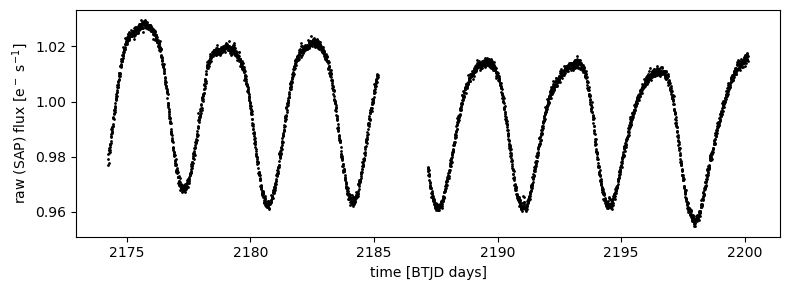

In [3]:
# execute this cell
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, star["sap"]/np.nanmedian(star["sap"]), "k.", ms=2)
ax.set_xlabel("time [BTJD days]")
ax.set_ylabel("raw (SAP) flux [e$^-$ s$^{-1}$]")
fig.tight_layout()
px.savefig(fig, "0_sap")

## Problem 1) Pixels

A light curve is a sum over pixels.  So let's start from the pixels.

**Problem 1a**

Run the next two cells.  The first plots the median frame of the
target pixel file: the target is the cross, other catalog stars from the TESS
Input Catalog are circles, and the pipeline aperture is outlined.  The second
panel shows the wider "full frame image" (FFI) cutout with the footprint of
the target pixel file.

'/Users/yzb4en/dsfp/Session-27/Day4/fig/1a_median.png'

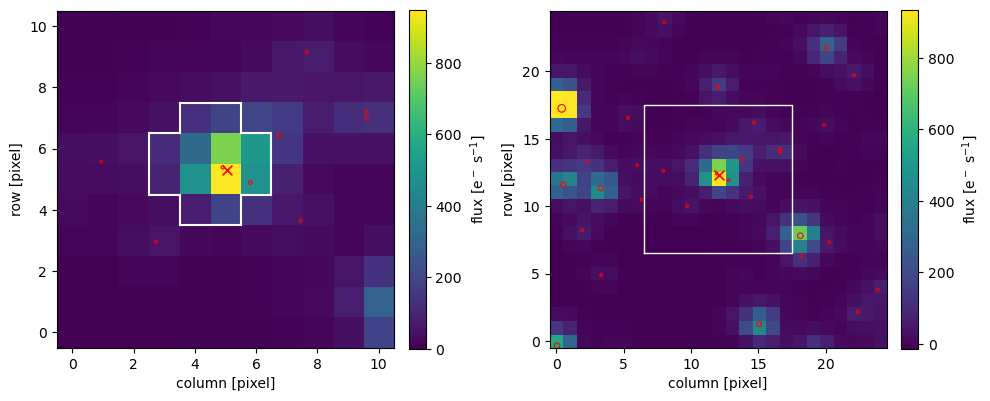

In [4]:
# execute this cell
median_img = np.median(tpf, axis=0)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
px.plot_image(axs[0], median_img, star, mask=aper)

wide_med = np.median(star["wide"], axis=0)
px.plot_image(axs[1], wide_med, star, wide=True,
              vmax=np.percentile(wide_med, 99.5))
c, r = star["wide_origin"]
ny, nx = aper.shape
axs[1].plot([c - 0.5, c + nx - 0.5, c + nx - 0.5, c - 0.5, c - 0.5],
            [r - 0.5, r - 0.5, r + ny - 0.5, r + ny - 0.5, r - 0.5],
            c="w", lw=1)
fig.tight_layout()
px.savefig(fig, "1a_median")

The catalog stars in the target pixel file, sorted by distance from
the target:

In [5]:
# execute this cell
col0, row0 = star["src_col"][0], star["src_row"][0]
dist = np.hypot(star["src_col"] - col0, star["src_row"] - row0)
sep = (dist * u.pix * px.PIXEL_SCALE).to(u.arcsec)
for i in np.argsort(dist):
    inside = aper[int(round(star["src_row"][i])),
                  int(round(star["src_col"][i]))]
    print(f"TIC {star['src_ticid'][i]:<11d} T = {star['src_tmag'][i]:5.2f}"
          f"  {dist[i]:4.1f} pix = {sep[i].value:5.1f} arcsec"
          f"  {'in aperture' if inside else ''}")

TIC 249037370   T = 11.48   0.0 pix =   0.0 arcsec  in aperture
TIC 672046074   T = 14.39   0.2 pix =   3.6 arcsec  in aperture
TIC 249037369   T = 14.20   0.9 pix =  18.0 arcsec  in aperture
TIC 249037372   T = 13.39   2.0 pix =  42.7 arcsec  
TIC 249037366   T = 14.70   2.9 pix =  61.1 arcsec  
TIC 249037028   T = 14.76   3.3 pix =  69.4 arcsec  
TIC 249037017   T = 15.22   4.1 pix =  86.7 arcsec  
TIC 249037383   T = 14.82   4.6 pix =  97.6 arcsec  
TIC 249037375   T = 13.80   4.8 pix = 101.8 arcsec  
TIC 249037376   T = 15.27   4.9 pix = 103.4 arcsec  


*Warm-up*: How many catalog stars are inside the pipeline aperture, and how many
are within three pixels of the target?  Could any of them plausibly
produce a percent-level signal in the aperture?

*Provide your answer to Problem 1a here*

**Problem 1b**

Now let's make our own light curves, with three apertures: one small
(radius 1 pixel), the pipeline aperture, and one large (radius 3.5
pixels).  The light curve is the sum over the pixels in the mask.
That line is yours.  The rest of the cell folds each light curve on
the claimed period (phase 0 is the flux minimum) and averages it in
25 phase bins.  Both panels show flux divided by the median flux in
that aperture: against time on the left, and binned in phase on the
right.  The cell prints the peak-to-peak amplitude of the binned
curve both ways: as a percentage of the median, and in electrons per
second.

<details>
<summary><em>Hint</em> (click to show)</summary>

`tpf[:, mask]` has shape `(n_time, n_pixels_in_mask)`.

</details>

small       3 pixels: amplitude  119.2 e-/s = 5.43% of the median
pipeline   12 pixels: amplitude  237.2 e-/s = 5.47% of the median
large      40 pixels: amplitude  268.3 e-/s = 4.53% of the median


'/Users/yzb4en/dsfp/Session-27/Day4/fig/1b_apertures.png'

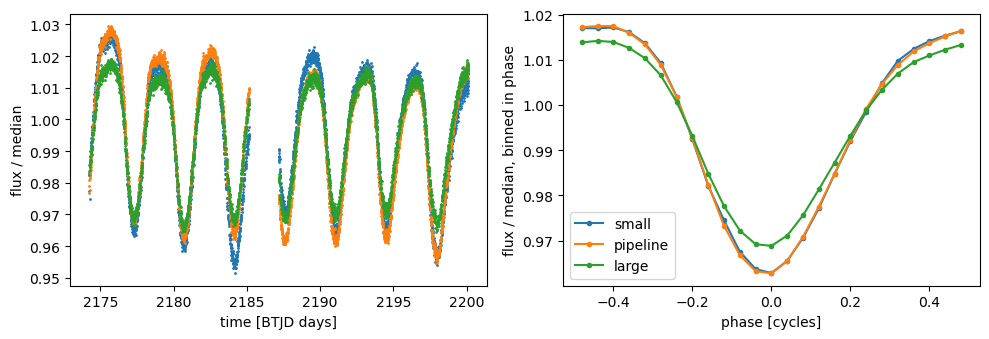

In [19]:
apertures = {
    "small": px.circular_aperture(aper.shape, col0, row0, 1.0),
    "pipeline": aper,
    "large": px.circular_aperture(aper.shape, col0, row0, 3.5),
}
phase = px.fold(t, period, t0)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for name, mask in apertures.items():
    lc = np.sum(tpf[:,mask],axis=1) # complete
    #print(lc)
    rel = lc / np.median(lc)
    #print(rel)
    # mean relative flux in each of 25 phase bins
    phase_bin, rel_bin, _ = px.bin_phase(phase, rel, 25)
    #print(phase_bin,rel_bin)
    amp_rel = np.nanmax(rel_bin) - np.nanmin(rel_bin)
    amp_abs = amp_rel * np.median(lc)
    axs[0].plot(t, rel, ".", ms=2, label=name)
    axs[1].plot(phase_bin, rel_bin, ".-", label=name)
    print(f"{name:9s} {mask.sum():3d} pixels: amplitude "
          f"{amp_abs:6.1f} e-/s = {100 * amp_rel:.2f}% of the median")
axs[0].set_xlabel("time [BTJD days]")
axs[0].set_ylabel("flux / median")
axs[1].set_xlabel("phase [cycles]")
axs[1].set_ylabel("flux / median, binned in phase")
axs[1].legend()
fig.tight_layout()
px.savefig(fig, "1b_apertures")

Which aperture shows the signal most strongly in relative terms? In
absolute terms? What would each number do, going from small to large,
if the variable were a different star two or three pixels away?

*Provide your answer to Problem 1b here*

**Problem 1c**

Good.  Now let's look at the pixels directly, with a difference image.
Average the frames near the flux minimum (`|phase| < 0.1`), average
the frames half a cycle away (`|phase| > 0.4`), and subtract the
second from the first.  Everything constant cancels.  What is left
is the image of whatever varies at this period.

The same operation on the wider FFI cutout is provided.

'/Users/yzb4en/dsfp/Session-27/Day4/fig/1c_difference.png'

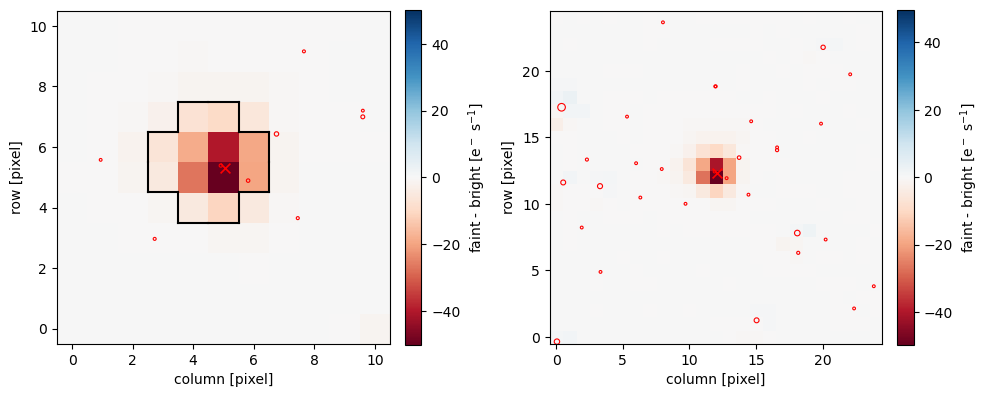

In [58]:
faint = star["tpf"][np.abs(phase) < 0.1].mean(axis=0) # complete
bright = star["tpf"][np.abs(phase) > 0.4].mean(axis=0) # complete
diff = faint-bright # complete

wphase = px.fold(star["wide_time"], period, t0)
wdiff = (star["wide"][np.abs(wphase) < 0.1].mean(axis=0)
         - star["wide"][np.abs(wphase) > 0.4].mean(axis=0))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
lab = "faint - bright [e$^-$ s$^{-1}$]"
for ax, img, wide in ((axs[0], diff, False), (axs[1], wdiff, True)):
    vmax = np.abs(img).max()
    px.plot_image(ax, img, star, wide=wide, cmap="RdBu", vmin=-vmax,
                  vmax=vmax, label=lab)
px.outline_mask(axs[0], aper, color="k")
fig.tight_layout()
px.savefig(fig, "1c_difference")

Now measure where the difference image peaks, as the centroid of its
strongest pixels.  The cell below builds the weights: `sig` is the
difference image with the sign flipped, so that the dimming is
positive, and with every pixel below 30% of the peak set to zero.
`xx` and `yy` hold the column and row of each pixel.  The centroid
implementation is yours.  The cell then prints the offset from the catalog
position of the target.

<details>
<summary><em>Hint</em> (click to show)</summary>

The centroid is the flux-weighted mean position.  With flux $f_i$ in
the pixel at column $x_i$ and row $y_i$,

$$x_c = \frac{\sum_i f_i\, x_i}{\sum_i f_i}, \qquad
  y_c = \frac{\sum_i f_i\, y_i}{\sum_i f_i}.$$

Here the flux is `sig`.

</details>

In [ ]:
yy, xx = np.indices(diff.shape)   # row and column of every pixel
sig = -diff                       # weights: the dimming, made positive
sig[sig < 0.3 * sig.max()] = 0    # keep only the strongest pixels
col_d = # complete
row_d = # complete

offset = np.hypot(col_d - col0, row_d - row0) * u.pix
print(f"difference image: ({col_d:.2f}, {row_d:.2f}); "
      f"target: ({col0:.2f}, {row0:.2f})")
print(f"offset = {offset.value:.2f} pix = "
      f"{(offset * px.PIXEL_SCALE).to(u.arcsec).value:.1f} arcsec")

Where is the variable? Is it the target? How far out does its image
extend, and whose apertures does it reach?

*Provide your answer to Problem 1c here*

## Problem 2) Cotrending

So far we've looked at one star.  But the spacecraft moves, the
focus changes, and light from the Earth and Moon sometimes scatters into the
cameras.  Cotrending is a regression of your star against the common trends
shared by all stars.

`star["nbr_flux"]` holds the raw light curves of 50 other stars on
the same camera and CCD.  Almost all are within half a magnitude of
the target: these are the nearby stars of similar brightness.

In [ ]:
# execute this cell
sap = star["sap"]
y = sap / np.median(sap) - 1        # target, relative flux - 1
nbr = star["nbr_flux"]              # (n_star, n_time), e-/s
print(f"{nbr.shape[0]} neighbors, T = {star['nbr_tmag'].min():.1f} to "
      f"{star['nbr_tmag'].max():.1f}; target T = {star['tmag']:.1f}")

**Problem 2a**

Let's start by looking at the data.  The next cell puts the neighbors in the
same units as the target (divide each by its median, subtract 1) and
plots the target and the first five neighbors.

In [ ]:
# execute this cell
nbr_rel = nbr / np.median(nbr, axis=1, keepdims=True) - 1

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(t, 100 * y, "k.", ms=2, label="target")
for i in range(5):
    ax.plot(t, 100 * nbr_rel[i] - 5 - 1.5 * i, ".", ms=2,
            label=f"neighbor {i}")
ax.set_ylabel("relative flux [%] + offset")
ax.set_xlabel("time [BTJD days]")
ax.legend(loc="upper right", ncol=3, fontsize=8, markerscale=4)
fig.tight_layout()
px.savefig(fig, "2a_neighbors")

What do the neighbors share? Can you see any of it in the target?

*Provide your answer to Problem 2a here*

**Problem 2b**

Now let's find the shared trends with PCA.  `pca_basis` below subtracts each
   star's mean and takes the singular value decomposition of the `(n_star,
   n_time)` array.  As a reminder/introduction, the [singular value
   decomposition](https://en.wikipedia.org/wiki/Singular_value_decomposition)
   factors our (n_star, n_time) array as a product of three matrices: a set of
   orthonormal time series (`basis` vectors, one per row), a weight for every
   star on each of those time series (`loadings`), and a diagonal matrix of
   singular values (`sing`) that sets the overall size of each term.  The terms
   are sorted by how much of the ensemble's variance they carry.  PCA is this
   decomposition applied after subtracting each star's mean.

   Running this cell computes and plots the first six principal components,
   with the target for comparison.

In [ ]:
# execute this cell
def pca_basis(rel_flux):
    '''Principal components of an ensemble of light curves.

    Args:
        rel_flux: Relative flux, shape (n_star, n_time).

    Returns:
        Tuple (basis, loadings, sing). basis has shape
        (n_comp, n_time) with orthonormal rows; loadings has shape
        (n_star, n_comp); sing holds the singular values.
    '''
    x = rel_flux - rel_flux.mean(axis=1, keepdims=True)
    loadings, sing, basis = np.linalg.svd(x, full_matrices=False)
    return basis, loadings, sing


basis_all, loadings_all, sing_all = pca_basis(nbr_rel)

fig, axs = plt.subplots(1, 2, figsize=(10, 5),
                        gridspec_kw={"width_ratios": [3, 1]})
axs[0].plot(t, y / np.std(y), "k.", ms=2)
for k in range(6):
    b = basis_all[k] / np.std(basis_all[k])
    axs[0].plot(t, b - 6 * (k + 1), ".", ms=2)
    print(f"component {k}: correlation with target = "
          f"{np.corrcoef(basis_all[k], y)[0, 1]:+.2f}")
axs[0].set_xlabel("time [BTJD days]")
axs[0].set_ylabel("target (top), components 0 to 5 [scaled]")
axs[1].semilogy(sing_all, "k.")
axs[1].set_xlabel("component")
axs[1].set_ylabel("singular value")
fig.tight_layout()
px.savefig(fig, "2b_components")

A few of the leading components look like the target.  That
should bother us: the target was excluded from the ensemble!

A principal component is a weighted sum of the stars.  So if a
component carries the target's signal, some star in the ensemble
carries it too.  Let's find that star.  Start with where the
ensemble stars are: `star["nbr_sep_px"]` is the distance of each
neighbor from the target, in pixels.  Flag any neighbor close enough
to share the target's light (Problem 1c).  You choose the threshold.
The rest of the cell folds every neighbor on the target's period to
check whether the flagged star carries the signal, and prints its
weights in the leading components: the weights of star `i` are
`loadings_all[i]`.

In [ ]:
# sep: distance of every neighbor from the target, in pixels
sep = star["nbr_sep_px"]
print("five closest neighbors [pixels]:",
      " ".join(f"{s:.1f}" for s in np.sort(sep)[:5]),
      f"; median: {np.median(sep):.0f}")
# close: True for neighbors near enough to catch the target's PSF wings
close = # complete
print(f"{close.sum()} neighbor(s) flagged")
bad = np.argmin(sep)  # the closest one

# does the flagged star carry the target's signal?
# amp_nbr: folded peak-to-peak amplitude of every neighbor
amp_nbr = np.array([px.fold_stats(phase, f)[0] for f in nbr_rel])
print(f"neighbor {bad}, TIC {star['nbr_ticid'][bad]}, T = "
      f"{star['nbr_tmag'][bad]:.2f}: folded amplitude "
      f"{100 * amp_nbr[bad]:.2f}%; median for the ensemble: "
      f"{100 * np.median(amp_nbr):.2f}%")
print(f"separation from target: {star['nbr_sep_px'][bad]:.1f} pixels; "
      f"median for the ensemble: {np.median(star['nbr_sep_px']):.0f}")
print("in the target pixel file catalog:",
      star["nbr_ticid"][bad] in star["src_ticid"])
print("its weights in components 0 to 5:",
      " ".join(f"{w:+.2f}" for w in loadings_all[bad, :6]))

# for comparison: the star with the largest weight in the component
# that looks most like the target
k_bad = np.argmax([abs(np.corrcoef(b, y)[0, 1]) for b in basis_all[:6]])
top = np.argmax(np.abs(loadings_all[:, k_bad]))
print(f"largest weight in component {k_bad}: neighbor {top} "
      f"({loadings_all[top, k_bad]:+.2f}), "
      f"{star['nbr_sep_px'][top]:.1f} pixels from the target")

fig, ax = plt.subplots(figsize=(6, 3.5))
phase_bin, nbr_bin, err = px.bin_phase(phase, nbr_rel[bad], 25)
ax.errorbar(phase_bin, 100 * nbr_bin, 100 * err, fmt="C3.", label="neighbor")
phase_bin, y_bin, err = px.bin_phase(phase, y, 25)
ax.plot(phase_bin, 100 * y_bin, "k.",
        label=f"target")
ax.set_xlabel("phase at the target's period")
ax.set_ylabel("relative flux [%]")
ax.legend()
fig.tight_layout()
px.savefig(fig, "2b_offender")

Remove the neighbor from the ensemble and recompute the basis.   Keep the
contaminated basis as `basis_all`: you'll want it below.

In [ ]:
# execute this cell
keep = ~close
basis, loadings, sing = pca_basis(nbr_rel[keep])

for k in range(6):
    print(f"component {k}: correlation with target = "
          f"{np.corrcoef(basis[k], y)[0, 1]:+.2f}")

*Provide your answer to Problem 2b here*

**Problem 2c**

We now have a basis.  Let's use it.  `cotrend` below fits a light
curve as a constant plus a linear combination of the first `n` basis
vectors, by least squares, and subtracts the basis part.  This is
Tuesday's linear model, with the basis vectors as the templates.
The `train` argument selects the cadences used to find the
coefficients; ignore it until Problem 4.

The fit is written.  The last step is yours: compute the flux with
the systematics removed.

<details>
<summary><em>Hint</em> (click to show)</summary>

The columns of the design matrix $A$ (`design`) are a constant and
the basis vectors $b_1, \ldots, b_n$.  The fit gives one coefficient
per column, $c = (c_0, c_1, \ldots, c_n)$ (`coef`).  The systematics
model is the basis part of the fit, without the constant.  Compute
the matrix product and subtract it from the flux $f$:

$$f_\mathrm{sysrem} = f - \sum_{k=1}^{n} c_k\, b_k
  = f - A_{[:,\,1:]}\; c_{[1:]}.$$

In numpy, `@` is the matrix product.

</details>

In [ ]:
def cotrend(flux, basis, n, train=None):
    '''Fit and remove the first n basis vectors from a light curve.

    Args:
        flux: Light curve, shape (n_time,).
        basis: Basis vectors, shape (n_comp, n_time).
        n: Number of basis vectors to use.
        train: Boolean mask of cadences used in the fit. Default all.

    Returns:
        Light curve with the fitted systematics model removed.
    '''
    design = np.vstack([np.ones(flux.size), basis[:n]]).T
    if train is None:
        train = np.ones(flux.size, dtype=bool)
    coef = np.linalg.lstsq(design[train], flux[train], rcond=None)[0]
    flux_sysrem = # complete: calculate the flux with systematics removed
    return flux_sysrem

First, let's see what would have happened had we not looked at the
ensemble: cotrend the target with five vectors from the contaminated
basis, `basis_all`.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, 100 * y, "k.", ms=2, label="raw")
ax.plot(  # complete
ax.set_xlabel("time [BTJD days]")
ax.set_ylabel("relative flux [%]")
ax.legend()
fig.tight_layout()
px.savefig(fig, "2c_contaminated")

Now use the clean basis with `N` = 2, 5, 10, and 30. `px.fold_stats`
returns the peak-to-peak amplitude of the folded light curve and the
scatter of the data around that fold. Watch both.

In [ ]:
# execute this cell
amp, scat = px.fold_stats(phase, y)
print(f"raw:    amplitude {100 * amp:.2f}%, scatter {1e6 * scat:.0f} ppm")

fig, axs = plt.subplots(4, 1, figsize=(8, 8), sharex=True, sharey=True)
for ax, n in zip(axs, (2, 5, 10, 30)):
    resid = cotrend(y, basis, n)
    amp, scat = px.fold_stats(phase, resid)
    print(f"N = {n:2d}: amplitude {100 * amp:.2f}%, "
          f"scatter {1e6 * scat:.0f} ppm")
    ax.plot(t, 100 * y, ".", c="0.7", ms=2)
    ax.plot(t, 100 * resid, "k.", ms=2)
    ax.set_ylabel(f"N = {n} [%]")
axs[-1].set_xlabel("time [BTJD days]")
fig.tight_layout()
px.savefig(fig, "2c_cotrend")

What does the contaminated basis do? With the clean basis, what
happens to the amplitude and to the scatter as `N` grows? Least
squares is supposed to make residuals smaller. Why is the corrected
light curve noisier than the raw one?

*Provide your answer to Problem 2c here*

## Problem 3) Filter response

Cotrending is a type filter.  How much of our signal does it remove?  We can't
answer that from the star's own signal, because we don't know the truth.  We
can however answer it for a signal we put there.  This is *injection and
recovery*, pointed at the correction instead of at the search.

**Problem 3**

`cotrend` is a linear operation on the light curve, so what it does
to a template alone is exactly what it does to that signal inside
the data.  *Whatever you do to the data, do to the template.*

For each period in `periods`, let's pass a unit sinusoid `s` through
`cotrend`, and measure the amplitude that comes back using Tuesday's
matched filter, $\hat{A} = \sum s\,d / \sum s^2$.  The loop over
`phi` averages over the phase of the sinusoid.

In [ ]:
periods = np.logspace(np.log10(0.25), np.log10(20), 20)  # days
# grid points to print: the nearest to these periods
show = [np.argmin(np.abs(periods - p)) for p in (1, 2, 3.5, 6, 10, 13, 20)]

fig, ax = plt.subplots(figsize=(6, 4))
for N_basis in (2, 4, 30):
    kept = np.zeros(periods.size)
    for j, p_sin in enumerate(periods):
        vals = []
        for phi in np.linspace(0, 2 * np.pi, 8, endpoint=False):
            s = np.sin(2 * np.pi * t / p_sin + phi)
            d = # complete
            a_hat = # complete
            vals.append(a_hat)
        kept[j] = np.mean(vals)
    ax.plot(periods, kept, "o-", label=f"N = {N_basis}")
    print(f"N_basis = {N_basis:2d}: " + "  ".join(
        f"{periods[j]:.1f} d: {kept[j]:.2f}" for j in show))
ax.axvline(period, c="0.6", ls=":")
ax.set_xscale("log")
ax.set_xlabel("period of the injected sinusoid [days]")
ax.set_ylabel("amplitude recovered / injected")
ax.legend()
fig.tight_layout()
px.savefig(fig, "3_response")

Which signals pass through untouched, and which do not?  The dotted
line is your star's period.  Why does the loss depend on period?  If
your science were a 10 day signal, what would you do differently?

*Provide your answer to Problem 3 here*

## Problem 4) Prediction

A least-squares fit always lowers the variance of the data
it was fit to.  That does noes mean the fit is locking on to anything real!
Here we'll ask: does the fit predict data it has not seen?

The TESS "sector" we've been looking at is in fact two orbits of the
spacecraft, in its 2:1 lunar resonant orbit.
Let's try fitting the coefficients on orbit 1, and applying them to orbit 2.

**Problem 4a**

Do this for two stars, with `N = 4`.  The first is a control: the
quietest neighbor, left out of its own basis.  The second is the
target.  Build the boolean mask `orbit1`, and pass it to `cotrend`
as `train`.  The cell prints the scatter in each orbit, before and
after: the standard deviation for the quiet star, and the scatter
about the fold for the target.

In [ ]:
orbit1 = # complete
orbit2 = ~orbit1
n_use = 4

# control: the quietest clean neighbor, left out of its own basis
quiet = np.argmin(np.where(keep, nbr_rel.std(axis=1), np.inf))
keep_q = keep & (np.arange(nbr.shape[0]) != quiet)
basis_q = pca_basis(nbr_rel[keep_q])[0]
y_q = nbr_rel[quiet]

pred_q = cotrend(y_q, basis_q, n_use, train=orbit1)
pred = # complete

fig, axs = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
rows = (("quiet neighbor", y_q, pred_q, False),
        ("target", y, pred, True))
for ax, (name, raw, corr, folded) in zip(axs, rows):
    print(name + (": scatter about the fold" if folded
                  else ": standard deviation"))
    for label, flux in (("raw", raw), ("fit on orbit 1", corr)):
        scat = []
        for sel in (orbit1, orbit2):
            if folded:
                scat.append(px.fold_stats(phase[sel], flux[sel])[1])
            else:
                scat.append(np.std(flux[sel]))
        print(f"  {label:15s} orbit 1: {1e6 * scat[0]:6.0f} ppm, "
              f"orbit 2: {1e6 * scat[1]:6.0f} ppm")
    ax.plot(t, 100 * raw, ".", c="0.7", ms=2, label="raw")
    ax.plot(t, 100 * corr, "k.", ms=2, label="fit on orbit 1")
    ax.axvspan(t[0], 2186.0, color="C0", alpha=0.15)
    ax.set_ylabel(f"{name} [%]")
axs[0].legend()
axs[1].set_xlabel("time [BTJD days]")
fig.tight_layout()
px.savefig(fig, "4a_predict")

For which star do the orbit 1 coefficients predict orbit 2?   Why?

*Provide your answer to Problem 4a here*

**Problem 4b**

Why did the target fail?  Look at the coefficients.  Every neighbor
has coefficients on the basis vectors too.  Together they tell us
what the instrument does to a star on this CCD.

The next cell compares them with the coefficients that least squares
gave the target in orbit 1.  Compute the mean and standard deviation
of the neighbors' coefficients, `mu` and `sd`.

In [ ]:
# the target's least-squares coefficients, fit on orbit 1 (as in 4a)
design = np.vstack([np.ones(t.size), basis[:n_use]]).T
coef_ls = np.linalg.lstsq(design[orbit1], y[orbit1], rcond=None)[0][1:]

# the neighbors' coefficients, from the SVD in 2b: (n_star, n_use)
coef_nbr = (loadings * sing)[:, :n_use]
# mu, sd: their mean and standard deviation, for each basis vector
mu = # complete
sd = # complete

fig, ax = plt.subplots(figsize=(6, 3.5))
for k in range(n_use):
    ax.plot(np.full(coef_nbr.shape[0], k), coef_nbr[:, k], ".", c="0.6",
            label="neighbors" if k == 0 else None)
    print(f"basis vector {k}: neighbors {mu[k]:+.2f} +/- {sd[k]:.2f}, "
          f"target {coef_ls[k]:+.2f} "
          f"({(coef_ls[k] - mu[k]) / sd[k]:+.0f} sigma)")
ax.plot(range(n_use), coef_ls, "C3o",
        label="target, least squares on orbit 1")
ax.set_xticks(range(n_use))
ax.set_xlabel("basis vector")
ax.set_ylabel("coefficient")
ax.legend()
fig.tight_layout()
px.savefig(fig, "4b_coefficients")

So let's tell the fit which coefficients are plausible.  Instead of
minimizing the residuals alone, minimize

$$\sum_i \frac{(y_i - m_i)^2}{\sigma^2}
  + \sum_k \frac{(c_k - \mu_k)^2}{s_k^2},$$

where $m$ is the model, $c_k$ are its coefficients, and $\mu_k$ and
$s_k$ are the ensemble's mean and standard deviation.  The second
term is a Gaussian prior on the coefficients.  This is called "ridge
regression", centered on the ensemble mean.

`cotrend_prior` below does this fit.  Let's use it on orbit 1 for each
`sigma` in the loop, and look at orbit 2 again.

In [ ]:
def cotrend_prior(flux, basis, n, mu, sd, sigma, train=None):
    '''Like cotrend, with a Gaussian prior on the coefficients.

    Args:
        flux: Light curve, shape (n_time,).
        basis: Basis vectors, shape (n_comp, n_time).
        n: Number of basis vectors to use.
        mu: Prior mean of each coefficient, shape (n,).
        sd: Prior standard deviation of each coefficient, shape (n,).
        sigma: Noise per cadence, in the units of flux.
        train: Boolean mask of cadences used in the fit. Default all.

    Returns:
        Light curve with the fitted systematics model removed.
    '''
    design = np.vstack([np.ones(flux.size), basis[:n]]).T
    if train is None:
        train = np.ones(flux.size, dtype=bool)
    # prior mean and precision (1 / variance); none on the constant
    mean = np.append(0, mu)
    prec = np.append(0, 1 / sd**2)
    lhs = design[train].T @ design[train] / sigma**2 + np.diag(prec)
    rhs = design[train].T @ flux[train] / sigma**2 + prec * mean
    coef = np.linalg.solve(lhs, rhs)
    return flux - design[:, 1:] @ coef[1:]


rows = [("raw", y), ("least squares", pred)]
# Let's tune sigma, the flux uncertainties, to alter how hard the data pull
# against the prior on the coefficients.
for sigma in (0.001, 0.02, 0.1, 1.0):
    flux = # complete with our new cotrending!
    rows.append((f"sigma = {100 * sigma:g}%", flux))

print(f"standard deviation of y: {100 * np.std(y):.1f}%")
print("target, fit on orbit 1: scatter about the fold")
for label, flux in rows:
    scat = [px.fold_stats(phase[sel], flux[sel])[1]
            for sel in (orbit1, orbit2)]
    print(f"  {label:15s} orbit 1: {1e6 * scat[0]:6.0f} ppm, "
          f"orbit 2: {1e6 * scat[1]:6.0f} ppm")

print("target, fit on all cadences: scatter about the fold")
full = cotrend_prior(y, basis, n_use, mu, sd, 0.1)
for label, flux in (("raw", y), ("least squares", cotrend(y, basis, n_use)),
                    ("sigma = 10%", full)):
    print(f"  {label:15s} {1e6 * px.fold_stats(phase, flux)[1]:6.0f} ppm")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, 100 * y, ".", c="0.7", ms=2, label="raw")
ax.plot(t, 100 * rows[4][1], "k.", ms=2,
        label="prior, sigma = 10%, fit on orbit 1")
ax.axvspan(t[0], 2186.0, color="C0", alpha=0.15)
ax.set_xlabel("time [BTJD days]")
ax.set_ylabel("target [%]")
ax.legend()
fig.tight_layout()
px.savefig(fig, "4b_prior")

Which `sigma` gives least squares back?  Which ones do no harm in
orbit 2?  The standard deviation of `y` is 2%.  Why is that still
too small?

*Provide your answer to Problem 4b here*

## Before the break

Open `LinkingTheLayers.ipynb`.  It is short.
Get your LLM running, or find a partner who has one.  If you do not
have data of your own on this laptop, start downloading one of the
listed datasets, so that you can start at 11:00.

## Extra

Bonus problem: **PSF photometry is a matched filter.** An aperture cannot
separate two stars two pixels apart. A model can. At each cadence the image is
a sum of point sources at known catalog positions,

$$d = \sum_k F_k\, P_k + n,$$

where $P_k$ is the PSF at the position of star $k$, flattened to a
vector of pixels. This is Tuesday's linear model with several
templates, and the fluxes $F_k$ come from one least-squares solve.

Using `px.gaussian_prf` as a crude PSF, fit the fluxes of every
catalog star in the target pixel file at every cadence. Fold the
light curve of the contaminated neighbor from 2b. Is the target's
signal still in it? What limits how well this works?

In [ ]:
# complete

*Provide your answer to Extra here*

## References

* Bryson et al. 2013, pixel-level tests for Kepler false positives,
  [2013PASP..125..889B](https://scixplorer.org/abs/2013PASP..125..889B/abstract)
* Twicken et al. 2018, Kepler data validation, difference images and
  centroids,
  [2018PASP..130f4502T](https://scixplorer.org/abs/2018PASP..130f4502T/abstract)
* Smith et al. 2012, Kepler PDC,
  [2012PASP..124.1000S](https://scixplorer.org/abs/2012PASP..124.1000S/abstract)
* Stumpe et al. 2012, Kepler PDC,
  [2012PASP..124..985S](https://scixplorer.org/abs/2012PASP..124..985S/abstract)
* Foreman-Mackey et al. 2015, fitting systematics and transits
  together,
  [2015ApJ...806..215F](https://scixplorer.org/abs/2015ApJ...806..215F/abstract)
* Wang et al. 2016, the causal pixel model,
  [2016PASP..128i4503W](https://scixplorer.org/abs/2016PASP..128i4503W/abstract)
* Lightkurve Collaboration 2018,
  [2018ascl.soft12013L](https://scixplorer.org/abs/2018ascl.soft12013L/abstract)